In [1]:
import os
import sys
sys.path.append(r"C:\Users\acostamendoza\projects\distance-project")
from path_setup import setup_project_path
setup_project_path()
from src.utils import create_new_result_dir
from src.LinearExperiment import LinearDevice, LinearPlots
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from suite2p.extraction import dcnv
from src.ActivityPipelines import ActivityLoader
from scipy.ndimage import gaussian_filter1d

%load_ext autoreload
%autoreload 2

mouse_name = 'SAM032'
record_date = '250421'
experiment_name = 'off-time'

data_dir = r'D:/data-distance-coding-project/processed-data/{record_date}_{mouse_name}_{experiment_name}/'.format(record_date=record_date, mouse_name=mouse_name, experiment_name=experiment_name)

if experiment_name =='off-time':
    on_times = ['2000', '500', '4000', '1000', '3000'] # actual order
elif experiment_name == 'rotation-time':
    on_times = ['1000', '250', '4000', '500', '2000'] # actual order
elif experiment_name == 'servo-time':
    on_times = ['4000', '100', '2000', '500'] # actual order

session_name = r'{record_date}_{mouse_name}_{experiment_name}_'.format(record_date=record_date, mouse_name=mouse_name, experiment_name=experiment_name)
session_dirs = []
for on_time in on_times:
    session_dir = os.path.join(data_dir, session_name + on_time)
    session_dirs.append(session_dir)
    os.makedirs(os.path.join(session_dir, 'suite2p', 'plane0'), exist_ok=True)
    os.makedirs(os.path.join(session_dir, 'stimulus'), exist_ok=True)

print(session_dirs[0])

D:/data-distance-coding-project/processed-data/250421_SAM032_off-time/250421_SAM032_off-time_2000


In [2]:
tau = 2
L_dict_dFF = {}
L_dict_spikes = {}
rotation_times = [int(k) for k in on_times]
sorted_indices = np.argsort(rotation_times)
response_total_dFF = []
response_total_spikes = []

for i, session_dir in enumerate(session_dirs):
    L_dict_dFF[i] = LinearDevice(session_dir, response_mode='dFF')
    L_dict_spikes[i] = LinearDevice(session_dir, response_mode='spikes-zscore', tau=tau)

    if i == 0:
        response_total_dFF = L_dict_dFF[i].response
        response_total_spikes = L_dict_spikes[i].response
    else:
        response_total_dFF = np.concatenate((response_total_dFF, L_dict_dFF[i].response), axis=1)
        response_total_spikes = np.concatenate((response_total_spikes, L_dict_spikes[i].response), axis=1)

# sort L_dict by the sorted_indices
L_dict_dFF = {i: L_dict_dFF[idx] for i, idx in enumerate(sorted_indices)}
L_dict_spikes = {i: L_dict_spikes[idx] for i, idx in enumerate(sorted_indices)}

Directory results already exists
Successfully loaded activity data
Stimulus file found
No servo movement time found, using 100ms
Synchronized stimulus and activity
Repeat stimulus on length distribution:
    12 repeats have length 81
    3 repeats have length 82
Set stimulus on length: 81
Directory results already exists
Computing spike deconvolution with tau = 2
Successfully loaded activity data
Stimulus file found
No servo movement time found, using 100ms
Synchronized stimulus and activity
Repeat stimulus on length distribution:
    12 repeats have length 81
    3 repeats have length 82
Set stimulus on length: 81
Directory results already exists
Successfully loaded activity data
Stimulus file found
No servo movement time found, using 100ms
Synchronized stimulus and activity
Repeat stimulus on length distribution:
    14 repeats have length 81
    1 repeats have length 82
Set stimulus on length: 81
Directory results already exists
Computing spike deconvolution with tau = 2
Successfull

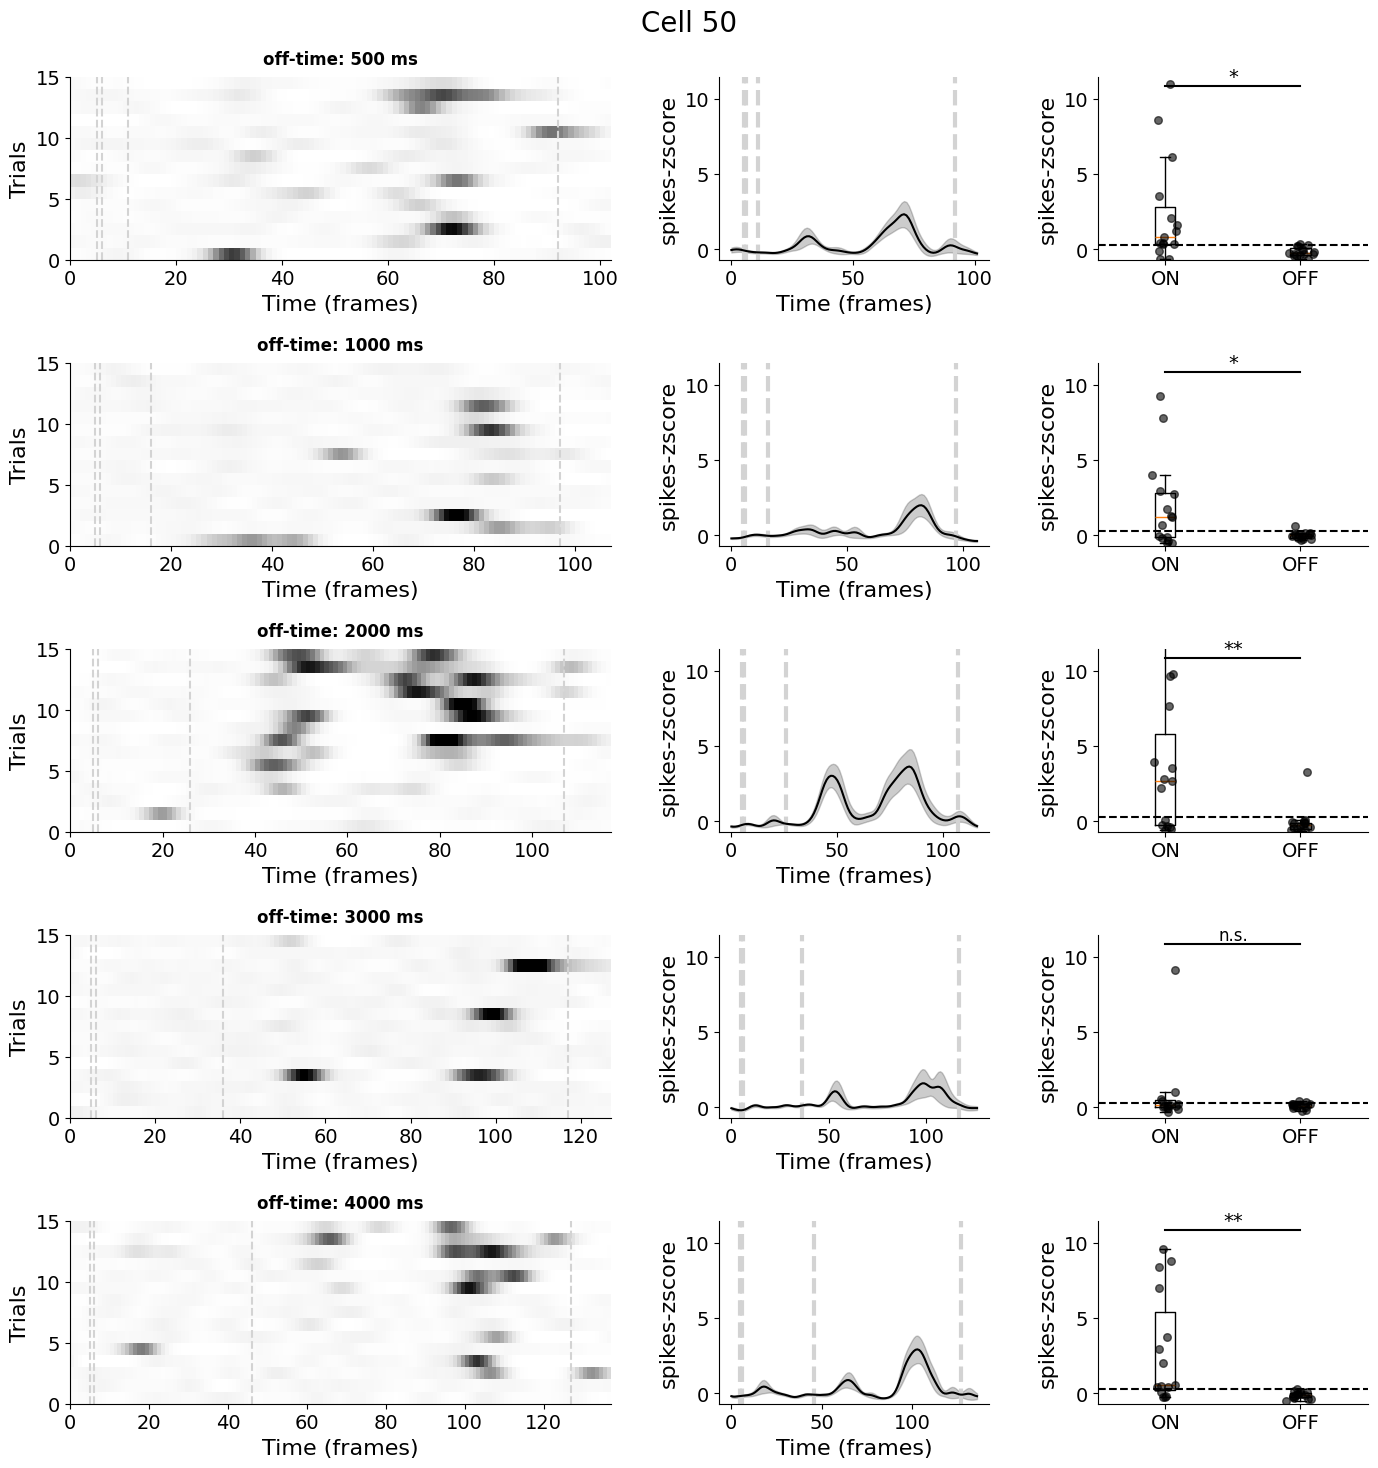

In [3]:
def plot_rotating_time_comparison(L_dict, response_total,cell, pre_time=1000, post_time=1000, distance=None):
    """
    Create a colormap visualization of neural traces for a given cell across multiple sessions.
    
    Parameters:
    -----------
    L_dict : dict
        Dictionary of LinearDevice objects.
    cell : int
        The cell ID to plot.
    pre_time : int, optional
        Time before stimulus onset in ms. Default is 2000.
    post_time : int, optional
        Time after stimulus offset in ms. Default is 2000.
    distance : int or list, optional
        Distance(s) to plot. If None, all distances are plotted.
        
    Returns:
    --------
    fig : matplotlib.figure.Figure
        The figure object.
    """

    # Create a figure with subplots for each session
    n_sessions = len(L_dict)
    fig, axs = plt.subplots(n_sessions, 3, figsize=(14, 3*n_sessions), 
                           gridspec_kw={'width_ratios': [2, 1, 1]})
    
    idx = np.where(L_dict[0].suite2p_id == cell)[0][0]
    vmin, vmax = np.percentile(np.array(response_total[idx]).flatten(), [0.25, 99.75])
    
    
    # If there's only one session, make sure axs is a 2D array
    if n_sessions == 1:
        axs = np.array([axs])
    
    # Process each session
    for session_idx, _ in enumerate(L_dict):


        if experiment_name == 'servo-time':
            pre_time = L_dict[session_idx].miniservo_pre_time + L_dict[session_idx].servo_movement_time + 500
            post_time = 1000

        if experiment_name == 'off-time':
            pre_time = L_dict[session_idx].miniservo_pre_time + L_dict[session_idx].servo_movement_time + 500
            post_time = 1000

        if distance is None:
            dist = None
            repeat_indices = np.arange(len(L_dict[session_idx].trial_sequence))
        else:
            dist = distance
            repeat_indices = np.where(L_dict[session_idx].trial_sequence == dist)[0]
            
        repeat_traces = []
        
        for repeat in repeat_indices:
            on_start, on_end = L_dict[session_idx].get_on_times(repeat)
            frames = (L_dict[session_idx].frames_time > (on_start-pre_time)) & (L_dict[session_idx].frames_time < (on_end+post_time))
            trace_length = L_dict[session_idx].on_length + int((pre_time + post_time)/100)
            
            # Make sure we don't exceed the available frames
            trace = L_dict[session_idx].response[idx, frames]
            if len(trace) >= trace_length:
                repeat_traces.append(trace[:trace_length].T)
        
        if not repeat_traces:
            continue
            
        repeat_traces = np.array(repeat_traces)
        repeat_traces_mean = np.mean(repeat_traces, axis=0)
        repeat_traces_sem = np.std(repeat_traces, axis=0)/np.sqrt(len(repeat_traces))
        
        # Add row title
        row_title = f"{experiment_name}: {on_times[sorted_indices[session_idx]]} ms"
        axs[session_idx, 0].text(0.5, 1.05, row_title, va='bottom', ha='center', 
                                 transform=axs[session_idx, 0].transAxes, 
                                 fontsize=12, fontweight='bold')
        
        if L_dict[session_idx].response_mode == 'spikes-zscore' or L_dict[session_idx].response_mode == 'spikes':
            cmap = 'Greys'
        elif L_dict[session_idx].response_mode == 'dFF' or L_dict[session_idx].response_mode == 'dFF-zscore':
            cmap = 'viridis'
        
        # Plot heatmap
        axs[session_idx, 0].pcolormesh(repeat_traces, cmap=cmap, vmin=vmin, vmax=vmax)
        # add axvline for when servo goes up
        axs[session_idx, 0].axvline(x=pre_time/100-L_dict[session_idx].miniservo_pre_time/100-L_dict[session_idx].servo_movement_time/100, color='lightgray', linestyle='--', linewidth=1.5)
        axs[session_idx, 0].axvline(x=pre_time/100-L_dict[session_idx].miniservo_pre_time/100, color='lightgray', linestyle='--', linewidth=1.5)
        axs[session_idx, 0].axvline(x=(pre_time/100), color='lightgray', linestyle='--', linewidth=1.5)
        axs[session_idx, 0].axvline(x=(pre_time/100+L_dict[session_idx].on_length), color='lightgray', linestyle='--', linewidth=1.5)
        axs[session_idx, 0].set_xlabel('Time (frames)')
        axs[session_idx, 0].set_ylabel('Trials')
        
        # Plot mean trace
        axs[session_idx, 1].axvline(x=pre_time/100-L_dict[session_idx].miniservo_pre_time/100-L_dict[session_idx].servo_movement_time/100, color='lightgray', linestyle='--', linewidth=3)
        axs[session_idx, 1].axvline(x=(pre_time-L_dict[session_idx].miniservo_pre_time)/100, color='lightgray', linestyle='--', linewidth=3)
        axs[session_idx, 1].axvline(x=(pre_time/100), color='lightgray', linestyle='--', linewidth=3)
        axs[session_idx, 1].axvline(x=(pre_time/100+L_dict[session_idx].on_length), color='lightgray', linestyle='--', linewidth=3)
        axs[session_idx, 1].plot(repeat_traces_mean, color='black')
        axs[session_idx, 1].set_xlabel('Time (frames)')
        axs[session_idx, 1].set_ylabel(L_dict[session_idx].response_mode)
        axs[session_idx, 1].fill_between(np.arange(len(repeat_traces_mean)), 
                                repeat_traces_mean - repeat_traces_sem, 
                                repeat_traces_mean + repeat_traces_sem, 
                                color='black', alpha=0.2)
        axs[session_idx, 1].set_ylim(vmin, vmax)
        
        # Analyze cell responsiveness and plot boxplot as third column
        is_responsive, p_val, on_max, off_max = L_dict[session_idx].analyze_cell_responsiveness(cell, distance=dist)
        
        # Plot boxplot of on and off
        axs[session_idx, 2].boxplot([on_max, off_max], patch_artist=False, showfliers=False)
        
        # Add scatter points to each column
        for j, data in enumerate([on_max, off_max], 1):
            # Add jitter to x positions for better visibility
            x = np.random.normal(j, 0.05, size=len(data))
            axs[session_idx, 2].scatter(x, data, alpha=0.6, s=30, color='black', zorder=3)
        
        axs[session_idx, 2].set_xticks([1, 2])
        axs[session_idx, 2].set_xticklabels(['ON', 'OFF'])
        axs[session_idx, 2].set_ylabel(L_dict[session_idx].response_mode)
        axs[session_idx, 2].set_ylim(vmin, vmax)
        
        # Add a horizontal line between the boxplots
        axs[session_idx, 2].plot([1, 2], [vmax * 0.95, vmax * 0.95], color='black', linewidth=1.5)
        axs[session_idx, 2].axhline(y=0.25, color='black', linestyle='--', linewidth=1.5)
        
        # Add significance indicators
        if not is_responsive:
            axs[session_idx, 2].text(1.5, vmax * 0.95, 'n.s.', color='black', ha='center', va='bottom', fontsize=12)
        elif p_val < 0.001:
            axs[session_idx, 2].text(1.5, vmax * 0.95, '***', color='black', ha='center', va='bottom', fontsize=14)
        elif p_val < 0.01:
            axs[session_idx, 2].text(1.5, vmax * 0.95, '**', color='black', ha='center', va='bottom', fontsize=14)
        elif p_val < 0.05:
            axs[session_idx, 2].text(1.5, vmax * 0.95, '*', color='black', ha='center', va='bottom', fontsize=14)
        else:
            axs[session_idx, 2].text(1.5, vmax * 0.95, 'n.s.', color='black', ha='center', va='bottom', fontsize=12)
    
    # Add suptitle to the figure
    fig.suptitle(f'Cell {cell}', fontsize=20)
    plt.tight_layout()
    
    return fig

fig = plot_rotating_time_comparison(L_dict_spikes, response_total_spikes, 50)

In [4]:
results_path = create_new_result_dir(data_dir, r'off-time-comparison')

for cell in L_dict_spikes[0].suite2p_id:
    fig = plot_rotating_time_comparison(L_dict_spikes, response_total_spikes, cell)
    fig.savefig(os.path.join(results_path, f'cell_{cell}_spikes_zscore.png'))
    plt.close(fig)

for cell in L_dict_dFF  [0].suite2p_id:
    fig = plot_rotating_time_comparison(L_dict_dFF, response_total_dFF, cell)
    fig.savefig(os.path.join(results_path, f'cell_{cell}_dFF.png'))
    plt.close(fig)

Directory off-time-comparison already exists


# Now for responsivness

In [3]:
pctg_responsive_dFF = []
ids_responsive_dFF = []
ids_not_responsive_dFF = []

for i in range(len(L_dict_dFF)):

    cells_responsive_stimulus = []
    cells_responsive_control = []
    non_responsive_cells = []
    for cell in L_dict_dFF[i].suite2p_id:
        is_responsive_stimulus = L_dict_dFF[i].analyze_cell_responsiveness(cell, None)[0]
        if is_responsive_stimulus:
            cells_responsive_stimulus.append(cell)
        elif not is_responsive_stimulus:
            non_responsive_cells.append(cell)

    # make a pie chart showing the percentage and number of responsive and unresponsive cells
    # Calculate total number of cells
    total_cells = len(L_dict_dFF[i].suite2p_id)

    # Create data for pie chart
    responsive_stimulus_count = len(cells_responsive_stimulus)
    responsive_control_count = len(cells_responsive_control)
    non_responsive_count = len(non_responsive_cells)

    pctg_responsive_dFF.append(responsive_stimulus_count/total_cells)
    ids_responsive_dFF.append(cells_responsive_stimulus)
    ids_not_responsive_dFF.append(non_responsive_cells)

In [4]:
pctg_responsive_spikes = []
ids_responsive_spikes = []
ids_not_responsive_spikes = []

for i in range(len(L_dict_spikes)):

    cells_responsive_stimulus = []
    cells_responsive_control = []
    non_responsive_cells = []
    for cell in L_dict_spikes[i].suite2p_id:
        is_responsive_stimulus = L_dict_spikes[i].analyze_cell_responsiveness(cell, None)[0]
        if is_responsive_stimulus:
            cells_responsive_stimulus.append(cell)
        elif not is_responsive_stimulus:
            non_responsive_cells.append(cell)

    # make a pie chart showing the percentage and number of responsive and unresponsive cells
    # Calculate total number of cells
    total_cells = len(L_dict_spikes[i].suite2p_id)

    # Create data for pie chart
    responsive_stimulus_count = len(cells_responsive_stimulus)
    responsive_control_count = len(cells_responsive_control)
    non_responsive_count = len(non_responsive_cells)

    pctg_responsive_spikes.append(responsive_stimulus_count/total_cells)
    ids_responsive_spikes.append(cells_responsive_stimulus)
    ids_not_responsive_spikes.append(non_responsive_cells)

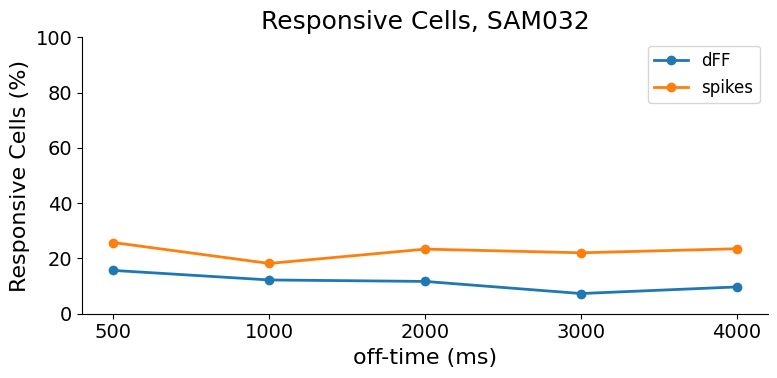

In [5]:
# on_times_sorted = np.array(on_times)[sorted_indices]
on_times_sorted = np.array(on_times)[sorted_indices]
plt.figure(figsize=(8, 4))
plt.plot(on_times_sorted, 100*np.array(pctg_responsive_dFF), marker='o', linewidth=2, label='dFF'   )
plt.plot(on_times_sorted, 100*np.array(pctg_responsive_spikes), marker='o', linewidth=2, label='spikes')
plt.title('Responsive Cells, ' + mouse_name)
plt.xlabel(experiment_name + ' (ms)')
plt.ylabel('Responsive Cells (%)')
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
# save the figure
plt.savefig(os.path.join(data_dir, r'responsive_cells_percentage.png'))

In [8]:
# Find the index for off_time 2000 is 2
off_time_2000_index = 3

# Get responsive cells for dFF and spikes at off_time 2000
responsive_dFF_cells = ids_responsive_dFF[off_time_2000_index]
responsive_spikes_cells = ids_responsive_spikes[off_time_2000_index]

# Find cells that are responsive in dFF but not in spikes
responsive_dFF_not_spikes = [cell for cell in responsive_dFF_cells if cell not in responsive_spikes_cells]

# Find cells that are responsive in spikes but not in dFF
responsive_spikes_not_dFF = [cell for cell in responsive_spikes_cells if cell not in responsive_dFF_cells]

# Print results
print(f"For off_time 2000:")
print(f"Total responsive cells in dFF: {len(responsive_dFF_cells)}")
print(f"Total responsive cells in spikes: {len(responsive_spikes_cells)}")
print(f"Cells responsive in dFF but not in spikes: {len(responsive_dFF_not_spikes)}")
print(f"Cells responsive in spikes but not in dFF: {len(responsive_spikes_not_dFF)}")

figure_path = create_new_result_dir(data_dir, r'responsive_cells_comparison_2000ms_are_responsive_in_dff_but_not_spikes')
for cell in responsive_dFF_not_spikes:
    fig = plot_rotating_time_comparison(L_dict_dFF, response_total_dFF, cell)
    fig.savefig(os.path.join(figure_path, f'cell_{cell}_dFF.png'))
    plt.close(fig)
    fig = plot_rotating_time_comparison(L_dict_spikes, response_total_spikes, cell)
    fig.savefig(os.path.join(figure_path, f'cell_{cell}_spikes.png'))
    plt.close(fig)

figure_path = create_new_result_dir(data_dir, r'responsive_cells_comparison_2000ms_are_responsive_in_spikes_but_not_dff')
for cell in responsive_spikes_not_dFF:
    fig = plot_rotating_time_comparison(L_dict_dFF, response_total_dFF, cell)
    fig.savefig(os.path.join(figure_path, f'cell_{cell}_dFF.png'))
    plt.close(fig)
    fig = plot_rotating_time_comparison(L_dict_spikes, response_total_spikes, cell)
    fig.savefig(os.path.join(figure_path, f'cell_{cell}_spikes.png'))
    plt.close(fig)


For off_time 2000:
Total responsive cells in dFF: 349
Total responsive cells in spikes: 232
Cells responsive in dFF but not in spikes: 167
Cells responsive in spikes but not in dFF: 50
Directory responsive_cells_comparison_2000ms_are_responsive_in_dff_but_not_spikes already exists
Creating directory: responsive_cells_comparison_2000ms_are_responsive_in_spikes_but_not_dff


: 

In [9]:
# check cells that are responsive in at least 3 of the 5 conditions
cells_responsive_in_at_least_3 = []
ids_responsive_3 = []
for cell in L_dict[0].suite2p_id:
    responsive_count = sum(cell in responsive_list for responsive_list in ids_responsive)
    if responsive_count >= 3:
        cells_responsive_in_at_least_3.append(cell)
        ids_responsive_3.append(cell)

figure_path = create_new_result_dir(data_dir, r'responsive_cells_in_at_least_3_conditions')
print(f"Cells responsive in at least 3 of the 5 conditions: {len(cells_responsive_in_at_least_3)}")

for cell in cells_responsive_in_at_least_3:
    fig = plot_rotating_time_comparison(L_dict, cell)
    fig.savefig(os.path.join(figure_path, f'cell_{cell}.png'))
    plt.close(fig)

Directory responsive_cells_in_at_least_3_conditions already exists
Cells responsive in at least 3 of the 5 conditions: 259


In [392]:
# plot non-responsive cells to stimulus and control
fig_path = create_new_result_dir(L.results_path, r'non_responsive_cells_stimulus')
for cell in cells_responsive_control:
    print(f'Cell {cell} ({cells_responsive_control.index(cell)+1}/{len(cells_responsive_control)})', end='\r')
    fig = LinearPlots(L).plot_all_traces_colormap(cell)
    filename = os.path.join(fig_path, f'cell_{cell}.png')
    fig.savefig(filename)
    plt.close(fig)
for cell in non_responsive_cells:
    print(f'Cell {cell} ({non_responsive_cells.index(cell)+1}/{len(non_responsive_cells)})', end='\r')
    fig = LinearPlots(L).plot_all_traces_colormap(cell)
    filename = os.path.join(fig_path, f'cell_{cell}.png')
    fig.savefig(filename)
    plt.close(fig)

Creating directory: non_responsive_cells_stimulus


# Plot location of the responsive cells


D:/data-distance-coding-project/processed-data/250417_SAM032_rotation-time/250417_SAM032_rotation-time_2000\suite2p\plane0
[4, 7, 12, 23, 24, 25, 27, 28, 32, 38, 44, 46, 47, 49, 51, 55, 56, 60, 72, 74, 75, 77, 79, 80, 81, 84, 85, 88, 90, 91, 92, 94, 95, 99, 101, 102, 105, 107, 110, 111, 118, 119, 121, 123, 124, 126, 128, 130, 132, 136, 138, 139, 142, 148, 155, 157, 158, 161, 163, 164, 166, 170, 172, 174, 181, 185, 190, 191, 204, 206, 210, 212, 214, 215, 217, 218, 220, 221, 222, 223, 224, 230, 231, 233, 234, 235, 236, 237, 239, 241, 246, 249, 253, 254, 255, 259, 262, 263, 264, 265, 267, 270, 272, 273, 274, 277, 287, 288, 289, 291, 295, 297, 299, 301, 302, 304, 307, 308, 309, 311, 312, 315, 316, 317, 323, 324, 331, 338, 339, 340, 341, 342, 343, 345, 346, 347, 351, 352, 356, 360, 361, 363, 364, 365, 366, 369, 370, 373, 374, 379, 380, 381, 385, 386, 387, 388, 389, 391, 393, 394, 395, 396, 397, 399, 401, 406, 407, 408, 410, 411, 412, 415, 419, 423, 424, 427, 428, 429, 433, 436, 438, 439, 44

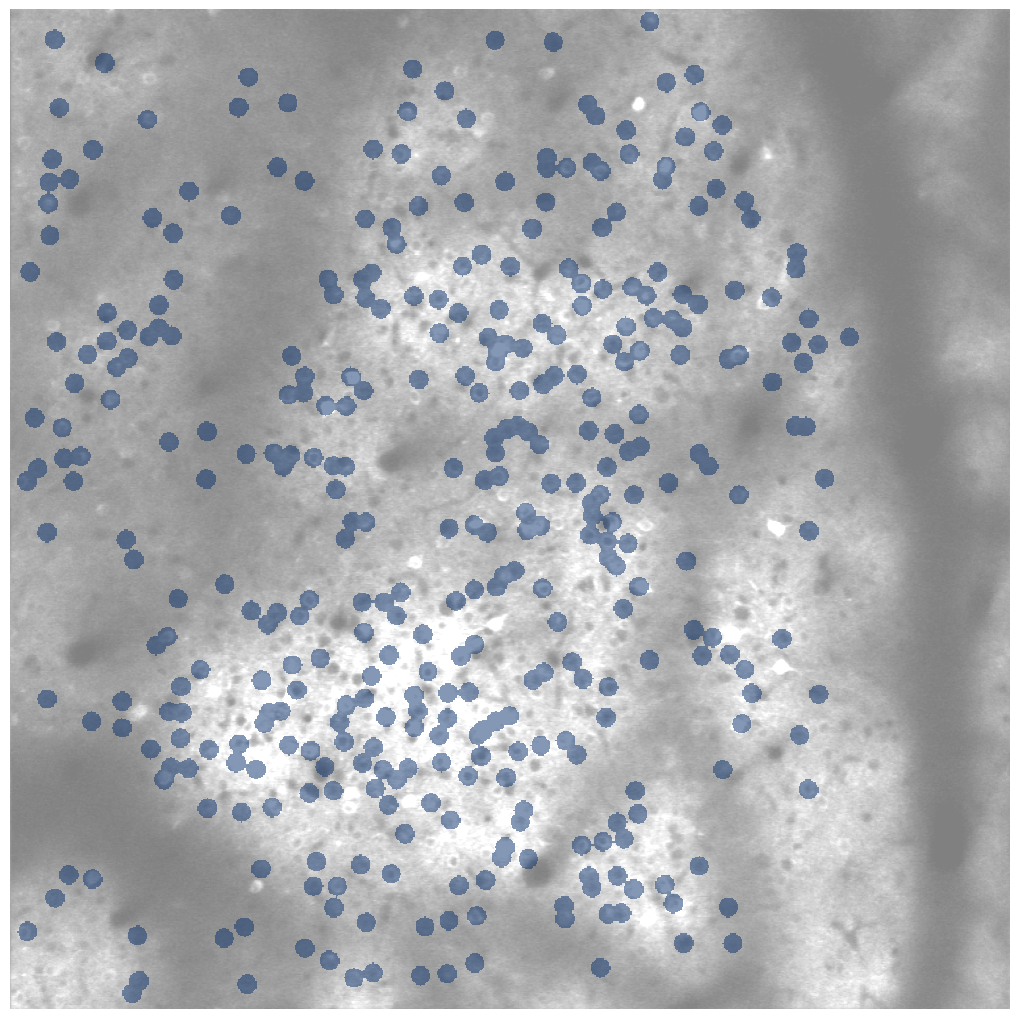

In [30]:
# get the indices of the cells with osi > 0.5
L = L_dict[3]
print(L.activity_path)

# Load the stat and ops files from the current folder
stat = np.load(L.activity_path + r'\stat.npy', allow_pickle=True)
ops = np.load(L.activity_path + r'\ops.npy', allow_pickle=True).item()

im = np.zeros((ops['Ly'], ops['Lx']))

# # get cells which osi > 0.5
tuned_cells = cells_responsive_stimulus
tuned_cells_idx = []
for cell in tuned_cells:
    tuned_cells_idx.append(np.where(L.suite2p_id == cell)[0][0])

print(tuned_cells_idx)

if len(tuned_cells_idx) > 0:
    for cell in tuned_cells_idx:
        
        ypix = stat[cell]['ypix'][~stat[cell]['overlap']]
        xpix = stat[cell]['xpix'][~stat[cell]['overlap']]
        # find the index of the cell in the cell_properties_df
        
        # Calculate the center of the cell
        center_y = np.mean(ypix)
        center_x = np.mean(xpix)
        
        # Create a circle mask with radius 10
        y, x = np.ogrid[:ops['Ly'], :ops['Lx']]
        dist_from_center = np.sqrt((x - center_x)**2 + (y - center_y)**2)
        circle_mask = dist_from_center <= 8
        
        # Add the circle to the image
        # im[circle_mask] = cell_properties_df.loc[cell_index, 'preferred_orientation'] # Set pixels to preferred orientation (normalized to 0-1)
        im[circle_mask] = 1
    

mean_img = ops['meanImg']
vmin = np.percentile(mean_img, 1)
vmax = np.percentile(mean_img, 99)

# Create the figure for display
plt.figure(figsize=(10, 10))
plt.imshow(ops['refImg'], alpha=0.5, cmap='gray', vmin=vmin, vmax=vmax)
# Create a mask for non-zero values
mask = im > 0
# Create a masked array where zeros are masked out
masked_im = np.ma.masked_where(im == 0, im)

plt.imshow(masked_im, alpha=0.5, vmin=0, vmax=1, cmap='Blues')
plt.axis('off')  # Turn off axes
plt.tight_layout(pad=0)  # Remove padding
# have colorbar to the right of the image

# Create a new figure specifically for saving
fig = plt.figure(figsize=(10, 10))
plt.imshow(ops['refImg'], alpha=0.6, cmap='gray', vmin=vmin, vmax=vmax)
plt.imshow(masked_im, alpha=1, vmin=0, vmax=1, cmap='Blues')
plt.axis('off')  # Turn off axes
plt.tight_layout(pad=0)  # Remove padding
plt.savefig(os.path.join(L.results_path, 'responsive_cells_stimulus_location.png'))
plt.close(fig)
